> Versión de portafolio. Se conservan las salidas históricas del trabajo académico. Las rutas absolutas de datos, cuando existían, se sustituyeron por nombres locales. Esta versión no se ha ejecutado de nuevo; consulte README y DATOS.md antes de reproducir.


# Tarea M-27 CD Javier Bueno Sanchez.

Preámbulo.

Realizar un análisis de agrupación por K-Means a una base de datos de manera que puedas generar conclusiones de acuerdo a diversas categorías.

Índice:

    1. Objetivo.

    2. Origen y contenido de la información.

    3. Importación de librerías y carga del conjunto de datos.

    4. Análisis exploratorio de los datos.

    5. Selección de variables numéricas.

    6. Codo y Silhouette con datos originales.

    7. K-Means original con k=3.

    8. PCA sin estandarización previa.

    9. Varianza explicada.

    10. Codo y Silhouette después de PCA.

    11. K-Means sobre PCA.
    
    12. Gráfico bidimensional.
    
    13. Comparación objetiva mediante tablas e índice de Rand ajustado.
    
    14. Conclusiones.

<b>1. Objetivo.</b>


Agrupar las observaciones mediante el algoritmo K-Means sin realizar transformaciones previas sobre los datos originales. Para ello, se determinará el número óptimo de clústeres mediante el método del codo y el coeficiente Silhouette.

Posteriormente, se repetirá el análisis después de reducir las cuatro variables originales a dos componentes principales mediante PCA. Los grupos obtenidos se representarán gráficamente utilizando las dos dimensiones resultantes.

Finalmente, se compararán ambos agrupamientos y se analizarán las ventajas prácticas de aplicar PCA antes de K-Means.

<b>2. Origen y contenido de la información.</b>


Extraer en línea la base de datos “Iris.csv” de la siguiente liga y agrégala a un DataFrame en Python. 

https://gist.github.com/netj/8836201

<b>3. Importación de librerías y carga del conjunto de datos.</b>

In [1]:
# Manipulación de datos.
import pandas as pd

df = pd.read_csv("iris.csv")

df.head()

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


<b>4. Análisis exploratorio de los datos.</b>

In [2]:
# Verificación de contenido del archivo.
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

display(df.head())
df.info()

Filas: 150
Columnas: 5


,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal.length  150 non-null    float64
 1   sepal.width   150 non-null    float64
 2   petal.length  150 non-null    float64
 3   petal.width   150 non-null    float64
 4   variety       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


El conjunto de datos contiene 150 observaciones y 5 columnas. Cuatro variables son numéricas de tipo float64 y representan medidas de las flores; la quinta variable, variety, es categórica de tipo object e identifica su variedad. No se detectaron valores nulos, por lo que no es necesario aplicar procedimientos de imputación.

<b> 5. Selección de variables numéricas.</b>

Nota técnica:

variety queda fuera porque K-Means solo trabaja con variables numéricas.

Tampoco debemos convertirla a números, porque representa la clasificación conocida y condicionaría artificialmente los grupos.

No aplicamos escalado ni ninguna otra transformación, tal como exige el primer inciso.

.copy() crea una matriz de trabajo independiente y evita modificar accidentalmente el DataFrame original.

In [3]:
# Selección de variables numéricas para el análisis
columnas_numericas = ["sepal.length", "sepal.width", "petal.length", "petal.width"]

X = df[columnas_numericas].copy()

# Verificación de la matriz de trabajo
display(X.head())
print("Dimensiones de X:", X.shape)

,sepal.length,sepal.width,petal.length,petal.width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Dimensiones de X: (150, 4)


In [4]:
# Importación de librerías necesarias.
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

Nota técnica:

<b>n_clusters=k:</b> prueba cada número de grupos.

<b>random_state=42:</b> permite reproducir el resultado.

<b>n_init=10:</b> ejecuta K-Means diez veces con distintos centroides iniciales y conserva la mejor solución.

<b>inertia_:</b> suma las distancias cuadradas de cada observación a su centroide. Siempre disminuye cuando aumenta k.

In [5]:
# Evaluación del número de clústeres (del 2 al 10) mediante el método del codo
rango_k = range(2, 11)
inercias = []

for k in rango_k:
    modelo_kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    
    modelo_kmeans.fit(X)
    inercias.append(modelo_kmeans.inertia_)

# Verificación de resultados
for k, inercia in zip(rango_k, inercias):
    print(f"k = {k}: inercia = {inercia:.4f}")

k = 2: inercia = 152.3480
k = 3: inercia = 78.8514
k = 4: inercia = 57.2285
k = 5: inercia = 46.4612
k = 6: inercia = 39.0400
k = 7: inercia = 34.3058
k = 8: inercia = 30.1324
k = 9: inercia = 28.2906
k = 10: inercia = 25.9709


<b>6. Codo y Silhouette con datos originales.</b>

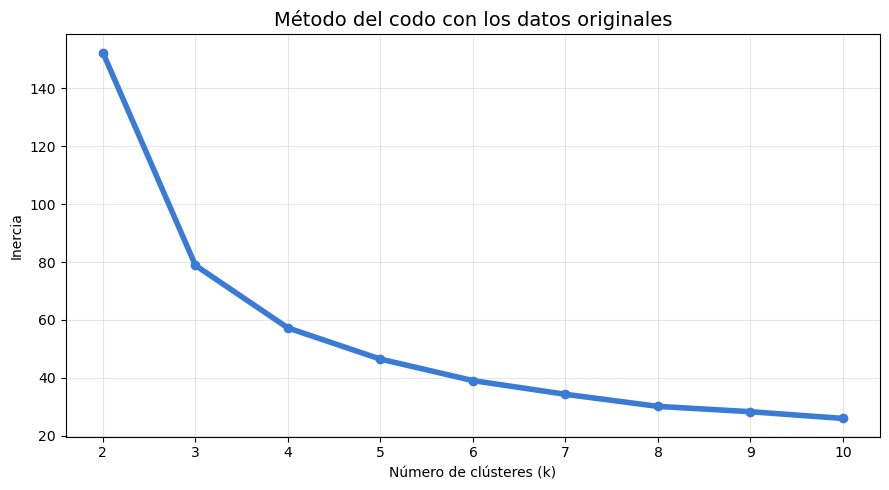

In [6]:
# Gráfico del coeficiente Silhouette con los datos originales.
plt.figure(figsize=(9, 5))

plt.plot(list(rango_k), inercias, marker="o", linewidth=4, color="#3A7BD5")

plt.title("Método del codo con los datos originales", fontsize=14)

plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(list(rango_k))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

<b>Interpretación:</b> 

El cambio de pendiente sugiere k=3

In [7]:
# Se añade la métrica.
from sklearn.metrics import silhouette_score

In [8]:
# Cálculo de coeficiente para cada valor de k:

# Evaluación del número de clústeres mediante Silhouette.
silhouettes = []

for k in rango_k:
    modelo_kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

    etiquetas = modelo_kmeans.fit_predict(X)

    puntuacion = silhouette_score( X, etiquetas)

    silhouettes.append(puntuacion)

# Verificación de resultados
for k, puntuacion in zip(rango_k, silhouettes):
    print(f"k = {k}: "
        f"Silhouette = {puntuacion:.4f}")

k = 2: Silhouette = 0.6810
k = 3: Silhouette = 0.5528
k = 4: Silhouette = 0.4981
k = 5: Silhouette = 0.4912
k = 6: Silhouette = 0.3648
k = 7: Silhouette = 0.3543
k = 8: Silhouette = 0.3487
k = 9: Silhouette = 0.3125
k = 10: Silhouette = 0.3180


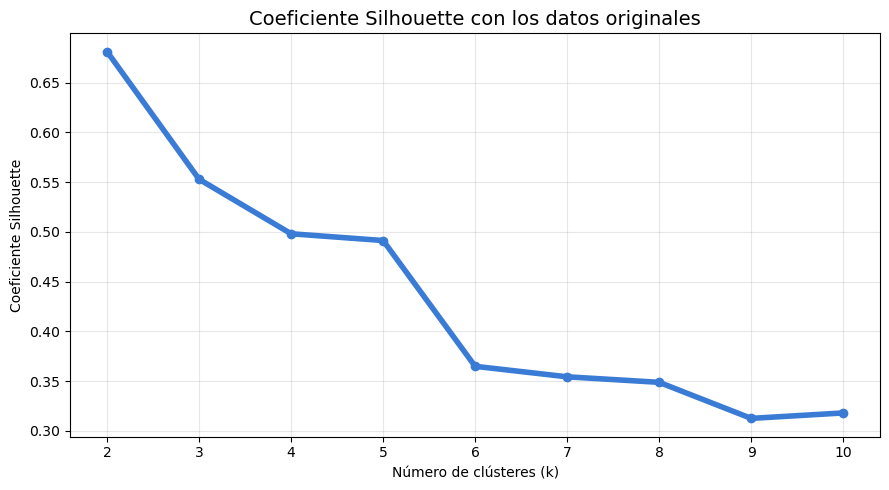

In [9]:
# Gráfico del método del codo después de PCA.
plt.figure(figsize=(9, 5))

plt.plot(list(rango_k), silhouettes, marker="o", linewidth=4, color="#3A7BD5")

plt.title("Coeficiente Silhouette con los datos originales", fontsize=14)
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Coeficiente Silhouette")
plt.xticks(list(rango_k))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

<b>Interpretación:</b>

El coeficiente Silhouette alcanza su valor máximo de 0.6810 con k=2, lo que indica que esta solución presenta la mejor combinación de cohesión interna y separación entre los grupos. Este resultado difiere del método del codo, que sugiere tres clústeres, porque ambos criterios evalúan aspectos distintos de la estructura de los datos.

<b>7. K-Means original con k=3.</b>

Nota técnica:

Selección del número de clústeres con dos resultados distintos:

Método del codo: k=3.
Silhouette: k=2, con 0.6810.

Esta discrepancia es información útil, no un fallo. Podremos efectuar y después comparar el agrupamiento utilizando k=3, porque el codo identifica tres grupos relevantes en la estructura de Iris. Silhouette prefiere dos porque una variedad está claramente separada, mientras las otras dos presentan mayor solapamiento.

In [10]:
# K-Means con los datos originales.
k_seleccionado = 3

kmeans_original = KMeans(n_clusters=k_seleccionado, random_state=42, n_init=10)

clusters_originales = kmeans_original.fit_predict(X)

# Incorporación de los grupos a una copia del DataFrame.
df_resultados = df.copy()
df_resultados["cluster_original"] = clusters_originales

# Verificación de la distribución.
print(df_resultados["cluster_original"].value_counts().sort_index())

display(df_resultados.head())

cluster_original
0    62
1    50
2    38
Name: count, dtype: int64


,sepal.length,sepal.width,petal.length,petal.width,variety,cluster_original
0,5.1,3.5,1.4,0.2,Setosa,1
1,4.9,3.0,1.4,0.2,Setosa,1
2,4.7,3.2,1.3,0.2,Setosa,1
3,4.6,3.1,1.5,0.2,Setosa,1
4,5.0,3.6,1.4,0.2,Setosa,1


Nota técnica:

Entrena K-Means con k=3.

Asigna a cada flor una etiqueta: 0, 1 o 2.

Conserva intacto el DataFrame original.

Añade los resultados a df_resultados.

<b>Importante:</b> los números de clúster no expresan orden ni categoría. El clúster 0 no es superior ni anterior al 1; son identificadores arbitrarios.

In [11]:
# Comparación entre los clústeres y las variedades reales.
tabla_cluster_variedad = pd.crosstab(df_resultados["cluster_original"],df_resultados["variety"])

display(tabla_cluster_variedad)

variety,Setosa,Versicolor,Virginica
cluster_original,,,
0,0,48,14
1,50,0,0
2,0,2,36


Esta tabla no se utiliza para entrenar el modelo. Funciona como validación externa para identificar:

- Qué variedad predomina en cada clúster.
- Cuáles variedades se separan claramente.
- Dónde se producen mezclas entre grupos.

<b>Interpretación de tabla:</b>

La comparación externa muestra que K-Means identifica completamente a la variedad Setosa, cuyas 50 observaciones forman el clúster 1. En cambio, Versicolor y Virginica presentan cierto solapamiento: el clúster 0 contiene principalmente observaciones Versicolor, mientras que el clúster 2 agrupa principalmente observaciones Virginica. Esto explica por qué el indicador Silhouette favoreció una solución de dos clústeres: Setosa está claramente separada, pero las otras dos variedades poseen características numéricas parcialmente similares.

In [12]:
# Perfil promedio de los clústeres obtenidos
perfil_clusters_originales = (df_resultados.groupby("cluster_original")[columnas_numericas].mean().round(2))

display(perfil_clusters_originales)

,sepal.length,sepal.width,petal.length,petal.width
cluster_original,,,,
0,5.90,2.75,4.39,1.43
1,5.01,3.43,1.46,0.25
2,6.85,3.07,5.74,2.07


<b>Interpretación:</b>

El perfil promedio confirma que los clústeres se diferencian principalmente por el tamaño de los pétalos. El clúster 1 reúne las flores con las dimensiones más pequeñas; el clúster 0 presenta medidas intermedias; y el clúster 2 contiene las flores de mayor tamaño. La longitud y el ancho del pétalo muestran una separación más marcada que las medidas del sépalo, por lo que parecen tener mayor influencia en la formación de los grupos.

<b>8. PCA sin estandarización previa.</b>

In [13]:
from sklearn.decomposition import PCA

# Reducción de cuatro variables a dos componentes principales
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

# Verificación de las dimensiones
print("Dimensiones originales:", X.shape)
print("Dimensiones después de PCA:", X_pca.shape)

Dimensiones originales: (150, 4)
Dimensiones después de PCA: (150, 2)


Nota técnica:

PCA(n_components=2) establece que las cuatro variables se reducirán a dos componentes.

fit_transform(X) aprende las combinaciones lineales que concentran la mayor variabilidad y transforma las 150 observaciones.

X_pca será una matriz con 150 filas y 2 columnas.

PCA sí es una transformación, pero corresponde al segundo ejercicio solicitado. Lo que no aplicamos es una transformación previa como StandardScaler.

<b>9. Varianza explicada.</b>

In [14]:
# Varianza explicada por cada componente principal
varianza_explicada = pca.explained_variance_ratio_

print(f"Varianza explicada por PC1: {varianza_explicada[0]:.4f}")
print(f"Varianza explicada por PC2: {varianza_explicada[1]:.4f}")
print(f"Varianza explicada acumulada: {varianza_explicada.sum():.4f}")

Varianza explicada por PC1: 0.9246
Varianza explicada por PC2: 0.0531
Varianza explicada acumulada: 0.9777


<b>Interpretación:</b>

El primer componente principal concentra aproximadamente el 92.46 % de la variabilidad de los datos y el segundo componente aporta el 5.31 %. En conjunto, ambos componentes explican el 97.77 % de la varianza. Por tanto, la reducción de cuatro a dos dimensiones mantiene prácticamente toda la información estructural relevante del conjunto de datos.

Nota técnica:

Es importante crear inercias_pca como una lista nueva. Así conservamos los resultados anteriores y podremos comparar ambos escenarios al final.

<b>10. Codo y Silhouette después de PCA.</b>

In [15]:
# Método del codo después de la reducción por PCA
inercias_pca = []

for k in rango_k:
    modelo_kmeans_pca = KMeans( n_clusters=k, random_state=42, n_init=10)

    modelo_kmeans_pca.fit(X_pca)
    inercias_pca.append(modelo_kmeans_pca.inertia_)

# Verificación de resultados
for k, inercia in zip(rango_k, inercias_pca):
    print(f"k = {k}: inercia = {inercia:.4f}")

k = 2: inercia = 137.1553
k = 3: inercia = 63.8199
k = 4: inercia = 42.2252
k = 5: inercia = 33.4802
k = 6: inercia = 26.1549
k = 7: inercia = 22.0409
k = 8: inercia = 17.9794
k = 9: inercia = 15.8410
k = 10: inercia = 14.0833


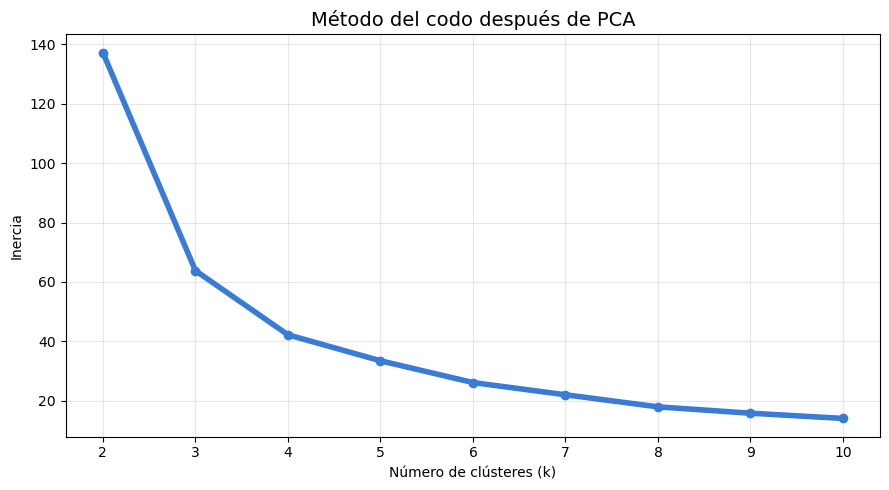

In [16]:
# Gráfico del método del codo después de PCA.
plt.figure(figsize=(9, 5))

plt.plot(list(rango_k), inercias_pca, marker="o", linewidth=4, color="#3A7BD5")

plt.title("Método del codo después de PCA", fontsize=14)
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(list(rango_k))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

<b>Interpretación:</b>

Después de reducir los datos a dos componentes principales, la inercia presenta su mayor disminución entre dos y tres clústeres. A partir de k=3, la reducción pierde intensidad, por lo que el método del codo vuelve a señalar tres clústeres como una solución adecuada. Este resultado coincide con el obtenido utilizando las cuatro variables originales.

In [17]:
# Evaluación mediante Silhouette después de PCA
silhouettes_pca = []

for k in rango_k:
    modelo_kmeans_pca = KMeans(n_clusters=k, random_state=42, n_init=10)

    etiquetas_pca = modelo_kmeans_pca.fit_predict(X_pca)

    puntuacion_pca = silhouette_score( X_pca, etiquetas_pca)

    silhouettes_pca.append(puntuacion_pca)

# Verificación de resultados
for k, puntuacion in zip(rango_k, silhouettes_pca):
    print(f"k = {k}: "f"Silhouette = {puntuacion:.4f}")

k = 2: Silhouette = 0.7057
k = 3: Silhouette = 0.5977
k = 4: Silhouette = 0.5577
k = 5: Silhouette = 0.5516
k = 6: Silhouette = 0.4428
k = 7: Silhouette = 0.4335
k = 8: Silhouette = 0.4513
k = 9: Silhouette = 0.4267
k = 10: Silhouette = 0.4196


<b>Interpretación de resultados:</b>

Después de aplicar PCA, el coeficiente Silhouette alcanza su valor máximo de 0.7057 con k=2. Por tanto, este indicador vuelve a señalar dos clústeres como la solución con mayor cohesión interna y separación. La puntuación supera el 0.6810 obtenido con los datos originales, lo que indica que los grupos presentan una separación ligeramente mayor en el espacio reducido. Este resultado es consistente con que PCA concentró en dos componentes la variabilidad más relevante para la estructura del conjunto de datos.

<b>11. K-Means sobre PCA.</b>

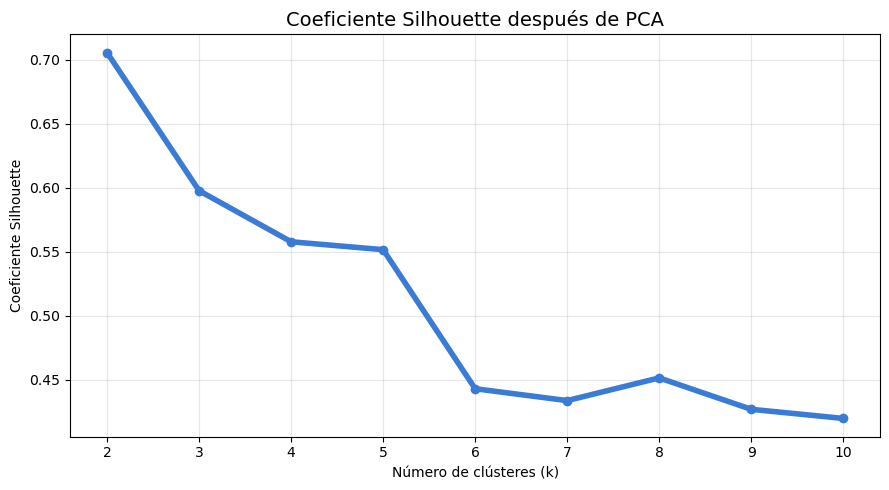

In [18]:
# Gráfico del coeficiente Silhouette después de PCA
plt.figure(figsize=(9, 5))

plt.plot(list(rango_k), silhouettes_pca, marker="o", linewidth=4, color="#3A7BD5")

plt.title("Coeficiente Silhouette después de PCA", fontsize=14)
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Coeficiente Silhouette")
plt.xticks(list(rango_k))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
# Ahora entrenamos K-Means sobre los dos componentes principales usando k=3, 
# para mantener una comparación equivalente con el agrupamiento original:

# K-Means sobre los datos reducidos mediante PCA
kmeans_pca = KMeans(n_clusters=k_seleccionado, random_state=42, n_init=10)

clusters_pca = kmeans_pca.fit_predict(X_pca)

# Incorporación de los resultados
df_resultados["PC1"] = X_pca[:, 0]
df_resultados["PC2"] = X_pca[:, 1]
df_resultados["cluster_pca"] = clusters_pca

# Verificación de la distribución
print(df_resultados["cluster_pca"].value_counts().sort_index())

display(df_resultados[["PC1", "PC2", "cluster_pca", "variety"]].head())

cluster_pca
0    39
1    50
2    61
Name: count, dtype: int64


,PC1,PC2,cluster_pca,variety
0,-2.684126,0.319397,1,Setosa
1,-2.714142,-0.177001,1,Setosa
2,-2.888991,-0.144949,1,Setosa
3,-2.745343,-0.318299,1,Setosa
4,-2.728717,0.326755,1,Setosa



<b>12. Gráfico bidimensional.</b>

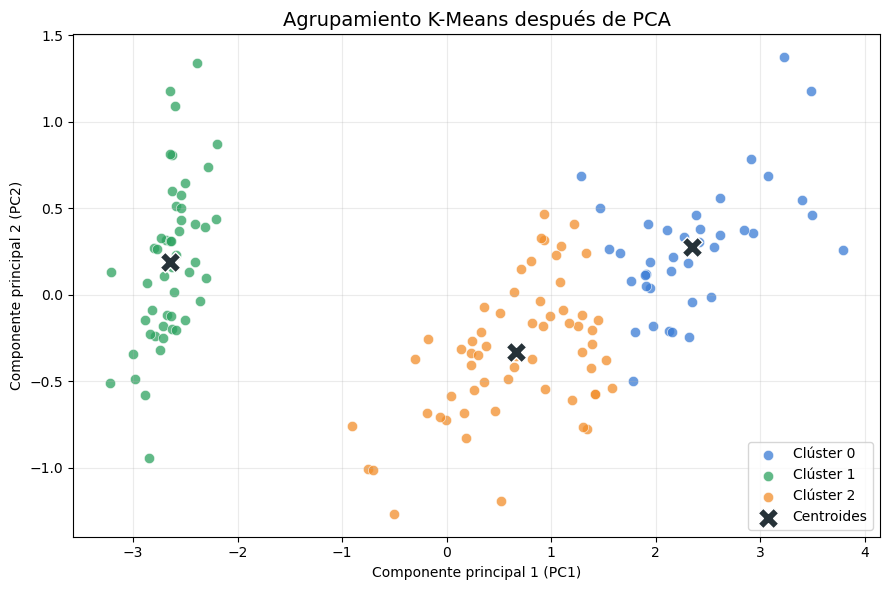

In [20]:
# Gráfico de los clústeres obtenidos después de PCA
plt.figure(figsize=(9, 6))

colores_clusters = {0: "#3A7BD5", 1: "#2CA25F", 2: "#F28E2B"}

for cluster in sorted(
    df_resultados["cluster_pca"].unique()):
    datos_cluster = df_resultados[
        df_resultados["cluster_pca"] == cluster]

    plt.scatter(datos_cluster["PC1"], datos_cluster["PC2"], label=f"Clúster {cluster}",
        color=colores_clusters[cluster], s=55, alpha=0.75, edgecolor="white", linewidth=0.5)

# Representación de los centroides
centroides_pca = kmeans_pca.cluster_centers_

plt.scatter(centroides_pca[:, 0], centroides_pca[:, 1], marker="X",
    s=220, color="#263238", edgecolor="white", linewidth=1, label="Centroides")

plt.title("Agrupamiento K-Means después de PCA", fontsize=14)

plt.xlabel("Componente principal 1 (PC1)")
plt.ylabel("Componente principal 2 (PC2)")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

<b>Interpretación:</b>

Los puntos representan las flores proyectadas sobre las dos dimensiones obtenidas mediante PCA. El símbolo X identifica el centroide de cada clúster.

La gráfica permite observar:

- Un grupo completamente separado, correspondiente a Setosa.
- Dos grupos próximos y parcialmente solapados, asociados principalmente con Versicolor y Virginica.
- Que PC1 concentra la mayor parte de la separación, algo coherente con su 92.46 % de varianza explicada.

In [21]:
from sklearn.metrics import adjusted_rand_score

# Comparación entre ambos agrupamientos
ari = adjusted_rand_score(
    df_resultados["cluster_original"],
    df_resultados["cluster_pca"]
)

print(f"Índice de Rand ajustado: {ari:.4f}")

Índice de Rand ajustado: 0.9803


Nota técnica:

Este indicador de Rand:

- Vale 1 cuando ambos agrupamientos son idénticos.
- Se aproxima a 0 cuando la coincidencia es similar a la esperada por azar.
- No se ve afectado por el número asignado arbitrariamente a cada clúster.

In [22]:
# Correspondencia entre los clústeres antes y después de PCA
tabla_comparacion = pd.crosstab(df_resultados["cluster_original"],df_resultados["cluster_pca"], 
    rownames=["Clúster original"], colnames=["Clúster después de PCA"])

display(tabla_comparacion)

Clúster después de PCA,0,1,2
Clúster original,,,
0,1,0,61
1,0,50,0
2,38,0,0


<b>Interpretación:</b>

La tabla de correspondencia muestra que los agrupamientos obtenidos antes y después de PCA son prácticamente iguales. Los 50 elementos del clúster original 1 conservaron su agrupamiento; 61 de los 62 elementos del clúster original 0 corresponden al clúster 2 después de PCA; y los 38 elementos del clúster original 2 corresponden al clúster 0 después de PCA. Únicamente una observación cambió de grupo. Por tanto, PCA conservó casi por completo la estructura de agrupamiento existente en las cuatro variables originales.

In [23]:
# Correspondencia de las etiquetas PCA con las originales
mapa_clusters_pca = {0: 2, 1: 1, 2: 0}

df_resultados["cluster_pca_equivalente"] = (df_resultados["cluster_pca"].map(mapa_clusters_pca))

# Identificación de las observaciones que cambiaron de grupo
observaciones_diferentes = df_resultados[
    df_resultados["cluster_original"] != df_resultados["cluster_pca_equivalente"]]

display(observaciones_diferentes[
        columnas_numericas
        + ["variety", "cluster_original", "cluster_pca", "cluster_pca_equivalente"]])

,sepal.length,sepal.width,petal.length,petal.width,variety,cluster_original,cluster_pca,cluster_pca_equivalente
50,7.0,3.2,4.7,1.4,Versicolor,0,0,2


<b>Interpretación:</b>

Solo una de las 150 observaciones cambió de agrupamiento después de aplicar PCA. Corresponde a una flor Versicolor con una longitud de sépalo relativamente elevada, característica que la sitúa cerca del límite entre los grupos predominantemente Versicolor y Virginica. Al reducir las cuatro variables a dos componentes, su posición respecto a los centroides cambió ligeramente y fue asignada al grupo asociado principalmente con Virginica. Esto confirma que la diferencia se produce en una zona de solapamiento y no representa una alteración general de la estructura de los datos.

La coincidencia directa es: 99.33%

<b>13. Comparación objetiva mediante tablas e índice de Rand ajustado.</b>

In [24]:
# Resumen comparativo de los resultados
comparacion_resultados = pd.DataFrame({
    "Criterio": ["Número de variables", "Clústeres sugeridos por el codo", "Clústeres sugeridos por Silhouette",
        "Silhouette con k=2", "Silhouette con k=3", "Distribución con k=3"], "Datos originales": [
        4, 3, 2, round(silhouettes[0], 4), round(silhouettes[1], 4), "62, 50 y 38"],
    "Después de PCA": [2, 3, 2, round(silhouettes_pca[0], 4), round(silhouettes_pca[1], 4), "61, 50 y 39"]})

display(comparacion_resultados)

,Criterio,Datos originales,Después de PCA
0,Número de variables,4,2
1,Clústeres sugeridos por el codo,3,3
2,Clústeres sugeridos por Silhouette,2,2
3,Silhouette con k=2,0.681,0.7057
4,Silhouette con k=3,0.5528,0.5977
5,Distribución con k=3,"62, 50 y 38","61, 50 y 39"


<b>Interpretación:</b>

Los dos procedimientos produjeron resultados prácticamente equivalentes. Tanto con las cuatro variables originales como con los dos componentes principales, el método del codo sugirió tres clústeres y Silhouette alcanzó su valor máximo con dos. Para k=3, únicamente una de las 150 observaciones cambió de grupo. Esta elevada coincidencia se confirma con un índice de Rand ajustado de 0.9803 y una correspondencia directa del 99.33 % después de homologar las etiquetas.

<b>14. Conclusiones.</b>

El análisis con K-Means mostró que los datos contienen una estructura de agrupamiento consistente. El método del codo señaló tres clústeres, mientras que el indicador Silhouette favoreció dos grupos por presentar mayor cohesión y separación. Esta diferencia se explica porque Setosa forma un grupo claramente separado, mientras Versicolor y Virginica tienen características parcialmente solapadas.

Después de aplicar PCA, los dos componentes explican el 97.77 % de la varianza. Los resultados de agrupamiento no fueron exactamente iguales, pero sí prácticamente equivalentes: solo una observación cambió de grupo y el índice de Rand ajustado alcanzó 0.9803.

La principal ventaja práctica de PCA fue reducir el conjunto de cuatro variables a dos dimensiones, facilitando la visualización directa de los clústeres y simplificando el análisis con una pérdida de información de apenas 2.23 %. Además, el coeficiente Silhouette aumentó tanto para k=2, de 0.6810 a 0.7057, como para k=3, de 0.5528 a 0.5977, lo que indica una separación ligeramente más clara en el espacio reducido.

Sin embargo, PCA también reduce la interpretación directa de las variables, porque los componentes representan combinaciones de las medidas originales. Por tanto, su ventaja principal en este ejercicio es la simplificación y visualización del problema, mientras que las variables originales siguen siendo más útiles para describir las características concretas de cada grupo.